# Importing libraries and reading data

In [161]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, RobustScaler, StandardScaler
from sklearn.metrics  import silhouette_score
import joblib


In [83]:
sns.set_theme(style='ticks', palette='colorblind', context='notebook')

In [84]:
df= pd.read_csv(r"data\customer_segmentation.csv")

# Data inspection and Cleaning

In [85]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [86]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [88]:
df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [89]:
today= dt.datetime.now().date()
df['age']= today.year - df['Year_Birth']

In [90]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,0,0,0,0,3,11,0,45


In [91]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
age                     0
dtype: int64

In [92]:
df.dropna(inplace=True)

In [93]:
df.duplicated().sum()

0

In [94]:
df['Dt_Customer']= pd.to_datetime(df['Dt_Customer'], dayfirst=True)

In [95]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,0,3,11,0,45


In [96]:
df['Children']= df['Kidhome'] + df['Teenhome']
df['amount_spent']= df['MntFishProducts'] + df['MntFruits'] + df['MntGoldProds']+ df['MntSweetProducts'] + df['MntWines'] + df['MntMeatProducts']
df['campaign']= df['AcceptedCmp1'] + df['AcceptedCmp2'] + df['AcceptedCmp3']+ df['AcceptedCmp4'] + df['AcceptedCmp5']


In [97]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age,Children,amount_spent,campaign
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,3,11,1,69,0,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,3,11,0,72,2,27,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,3,11,0,61,0,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,3,11,0,42,1,53,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,3,11,0,45,1,422,0


In [98]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'age', 'Children', 'amount_spent', 'campaign'],
      dtype='object')

In [99]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age,Children,amount_spent,campaign
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,2013-07-10 11:29:27.509025280,49.012635,305.091606,26.356047,166.995939,...,0.064079,0.013538,0.009477,3.0,11.0,0.150271,57.179603,0.947202,607.075361,0.298285
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,30.000000,0.000000,5.000000,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,24.000000,2.000000,16.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,49.000000,0.000000,69.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,174.500000,8.000000,68.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,56.000000,1.000000,396.500000,0.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-31 00:00:00,74.000000,505.000000,33.000000,232.250000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,67.000000,1.000000,1048.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,1.000000,1.000000,1.000000,3.0,11.0,1.000000,133.000000,3.000000,2525.000000,4.000000
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,NaN,28.948352,337.327920,39.793917,224.283273,...,0.244950,0.115588,0.096907,0.0,0.0,0.357417,11.985554,0.749062,602.900476,0.679209


# EDA and Data visualization

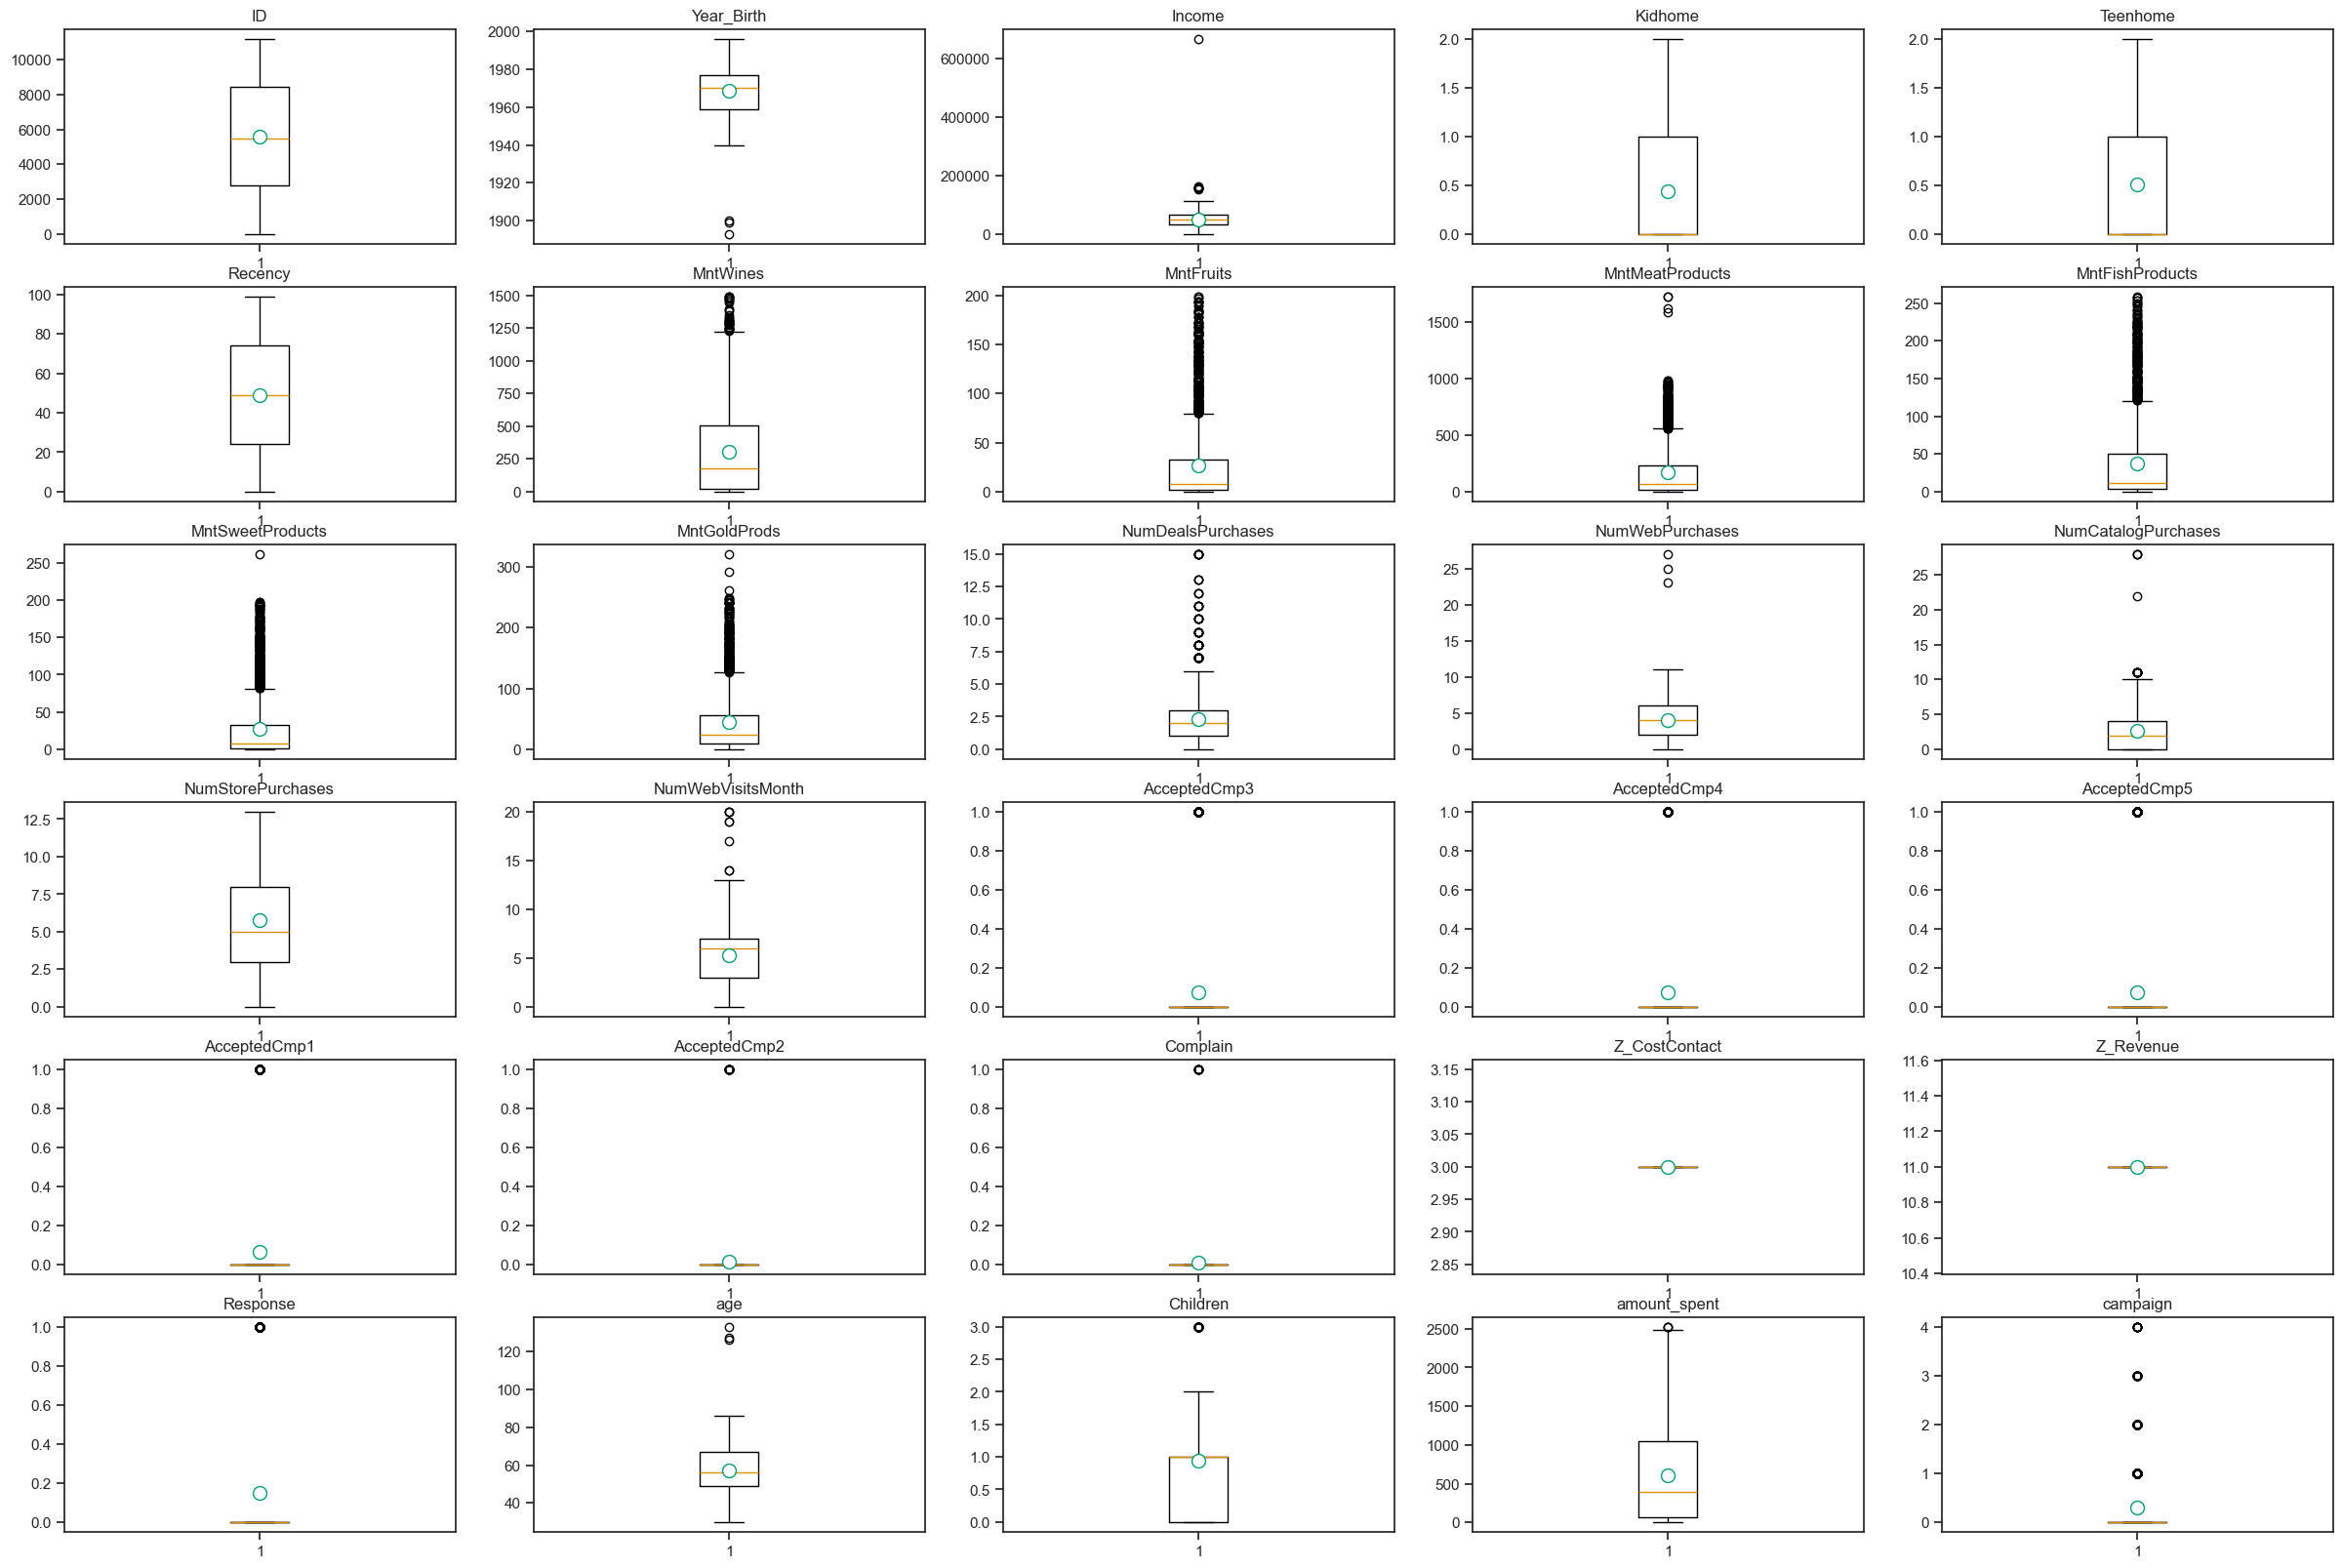

In [100]:

fig,axes= plt.subplots(ncols=5,nrows=6, figsize= (30,20))
axes= axes.reshape(-1)
for i,col in enumerate(df.select_dtypes(include=np.number)):
    axes[i].boxplot(df[col],showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
    axes[i].set_title(col)

plt.show()
    

In [101]:
# Fixing outliers

def outlier(col, df):
  Q1= df[col].quantile(0.25)
  Q3= df[col].quantile(0.71)
  IQR= Q3 - Q1
  upper_limit= Q3 + 1.5 * IQR
  lower_limit= Q1- 1.5 * IQR
  df[col]= df[col].where((df[col] <= upper_limit ) & (df[col]>= lower_limit), IQR)

In [102]:
outlier('Income', df)

In [103]:
outlier('age', df)

In [104]:
df= df[df['age']> df['age'].min()]

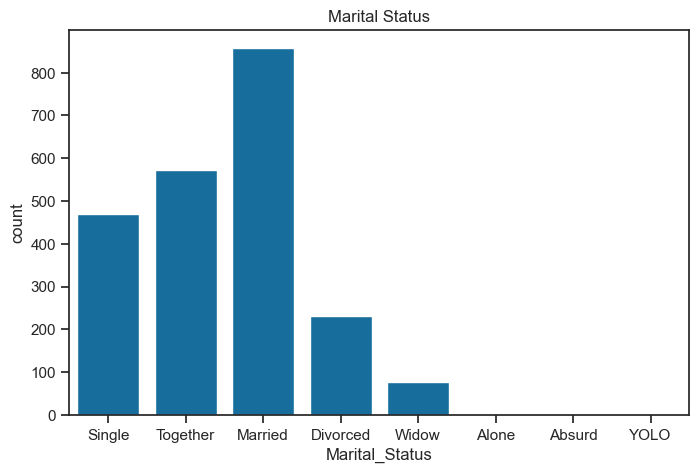

In [105]:
plt.figure(figsize=(8,5))
sns.countplot(data= df, x= 'Marital_Status')


plt.title('Marital Status')
plt.show()

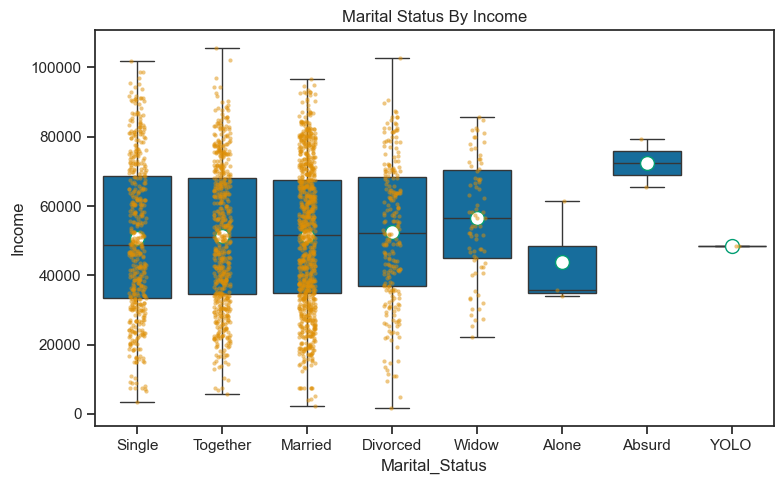

In [106]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Marital_Status', y='Income', data=df,showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
sns.stripplot(x='Marital_Status', y='Income', data=df,alpha=0.5,size=3,jitter=True)

plt.title('Marital Status By Income')
plt.tight_layout()
plt.show()

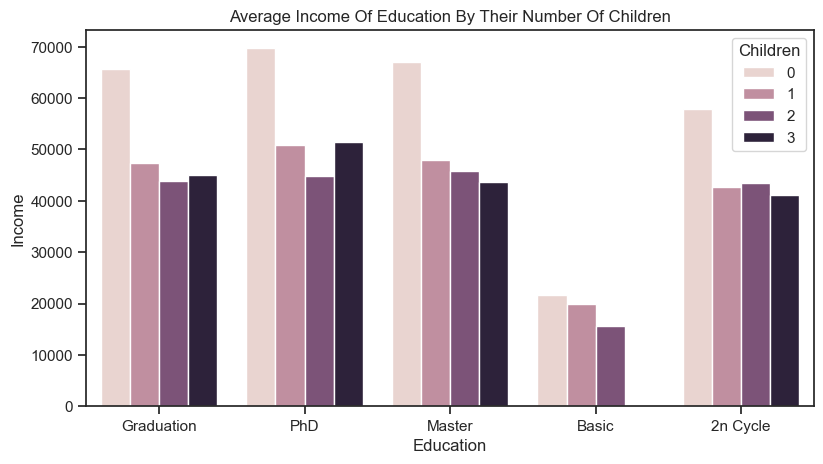

In [107]:
plt.figure(figsize=(8.4,4.6))

sns.barplot(data= df, x='Education', y='Income', estimator='mean', hue='Children',errorbar=None)

plt.tight_layout()
plt.title('Average Income Of Education By Their Number Of Children')
plt.show()

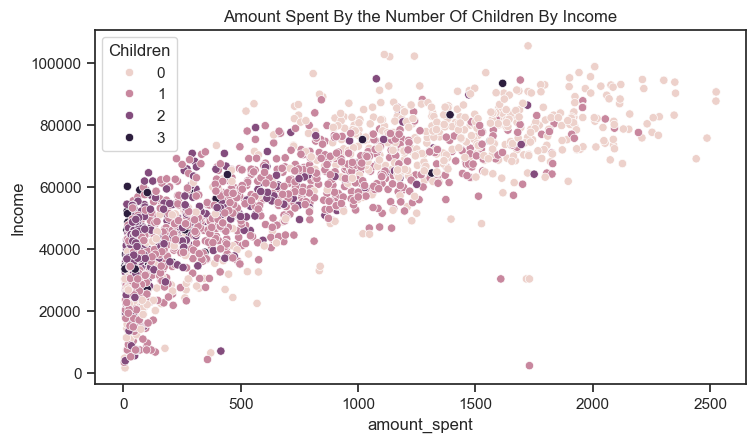

In [108]:
plt.figure(figsize=(8.4,4.6))

sns.scatterplot(data=df, y='Income', x='amount_spent', hue= 'Children',)
plt.title('Amount Spent By the Number Of Children By Income')

plt.show()

In [109]:
df.Income.describe()

count      2213.000000
mean      51507.673520
std       20677.442707
min        1730.000000
25%       34935.000000
50%       51141.000000
75%       68142.000000
max      105471.000000
Name: Income, dtype: float64

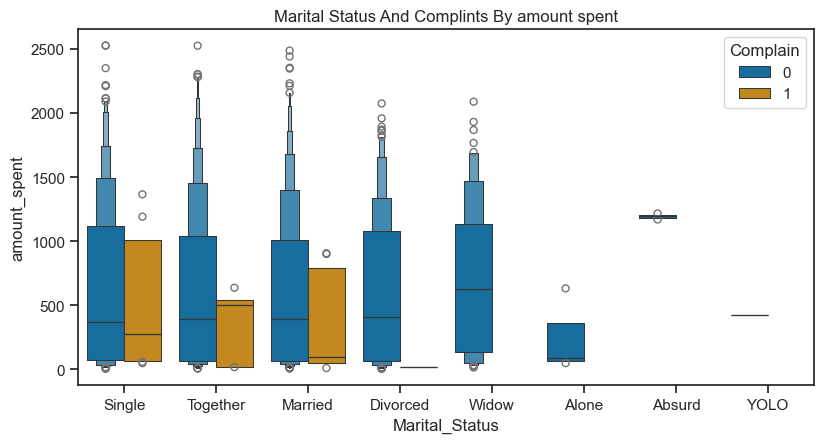

In [110]:
plt.figure(figsize=(8.4,4.6))

sns.boxenplot(data=df, x='Marital_Status', y='amount_spent', hue='Complain')

plt.title('Marital Status And Complints By amount spent')
plt.tight_layout()
plt.show()

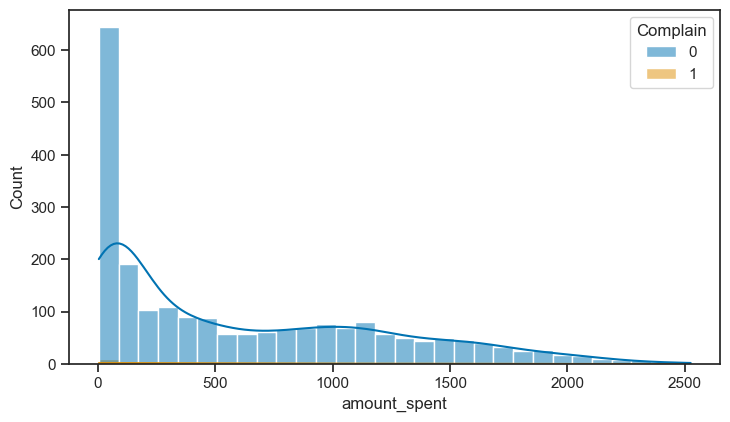

In [111]:
plt.figure(figsize=(8.4,4.6))

sns.histplot(data= df, hue= 'Complain', x='amount_spent', bins=30, kde= True)

plt.show()

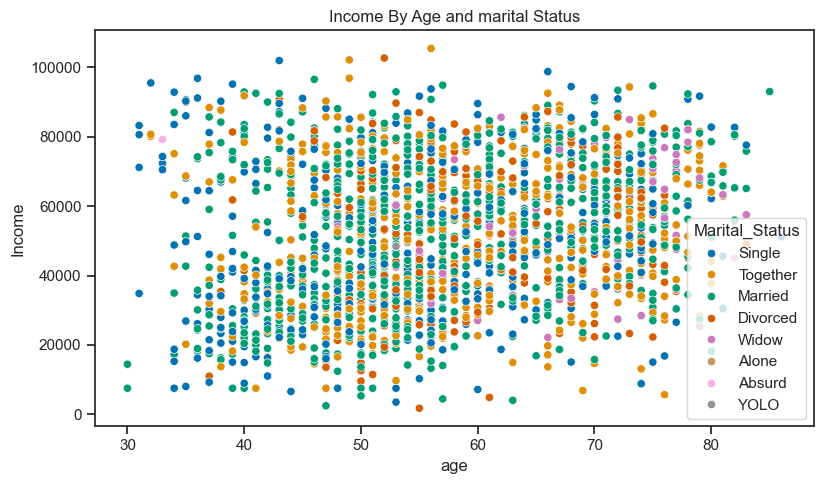

In [112]:
plt.figure(figsize=(8.4,5))

sns.scatterplot(data=df, x='age', y= 'Income', hue='Marital_Status')


plt.title('Income By Age and marital Status')
plt.tight_layout()
plt.show()

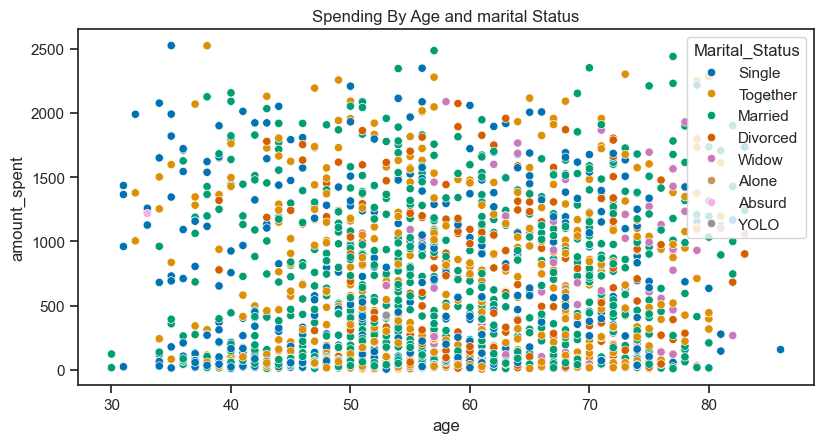

In [113]:
plt.figure(figsize=(8.4,4.6))


sns.scatterplot(data=df, x='age', y= 'amount_spent', hue='Marital_Status')
plt.title('Spending By Age and marital Status')
plt.tight_layout()
plt.show()

In [114]:
df[ 'Year_Birth'].value_counts().head()

Year_Birth
1976    89
1971    86
1975    83
1972    78
1978    76
Name: count, dtype: int64

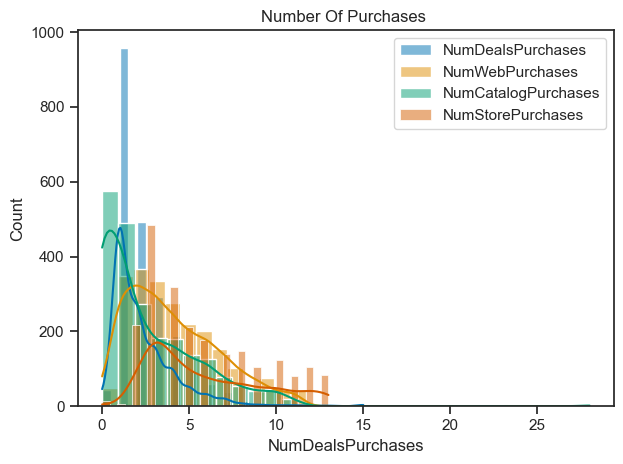

In [115]:
col= ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases',]
for i,col in enumerate(col):
  sns.histplot(data=df, x=df[col], bins=30, kde=True, label=col)
  plt.title("Number Of Purchases ")
plt.legend()
plt.tight_layout()
plt.show()

In [116]:
df.groupby('NumWebPurchases')['NumWebVisitsMonth'].agg(['mean','sum', 'count']).reset_index().head()

,NumWebPurchases,mean,sum,count
0,0,5.979167,287,48
1,1,6.239193,2165,347
2,2,5.716621,2098,367
3,3,5.131737,1714,334
4,4,4.115942,1136,276


In [117]:
df.Complain.value_counts()

Complain
0    2193
1      20
Name: count, dtype: int64

In [118]:
age_by_complain=df[df['Complain']== 1]
age_by_complain=age_by_complain[['age','Complain']].value_counts().reset_index().sort_values('count', ascending=False)
age_by_complain.head()

,age,Complain,count
0,67,1,3
1,48,1,2
2,72,1,2
3,31,1,1
4,38,1,1


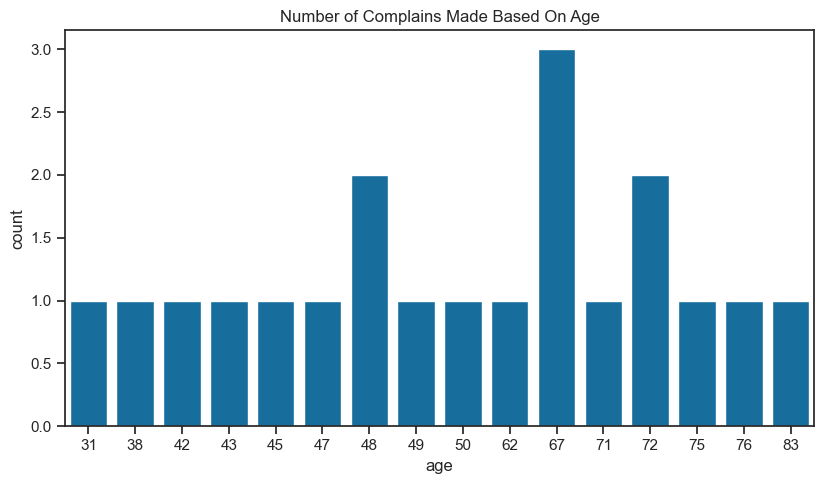

In [119]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=age_by_complain, x='age', y='count')


plt.title('Number of Complains Made Based On Age')
plt.tight_layout()
plt.show()

In [120]:
df.groupby('Children')['amount_spent'].agg(['mean','sum','count'])

,mean,sum,count
Children,,,
0,1104.064873,697769,632
1,475.473543,530153,1115
2,246.735577,102642,416
3,255.500000,12775,50


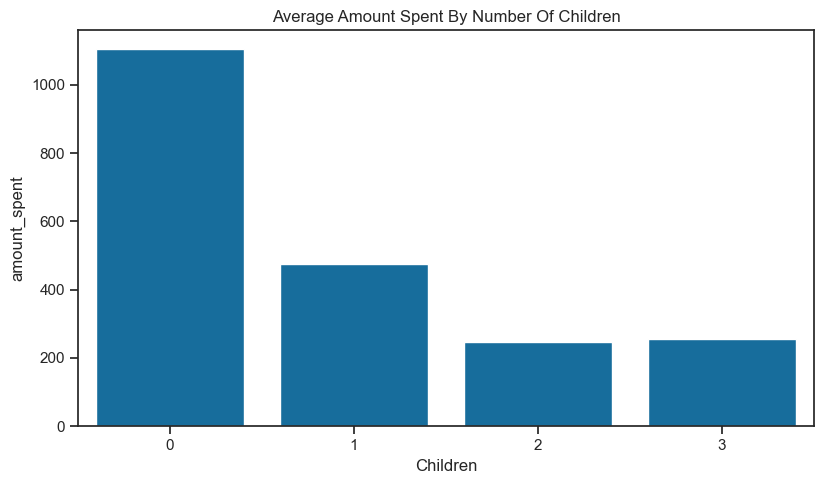

In [121]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'Children', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Number Of Children')
plt.tight_layout()
plt.show()

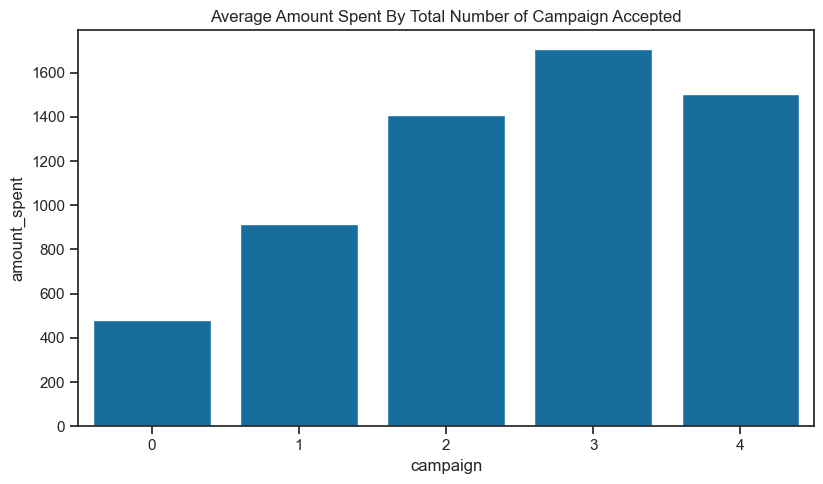

In [122]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'campaign', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Total Number of Campaign Accepted')
plt.tight_layout()
plt.show()

In [123]:
df.groupby('Education')['amount_spent'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,499.489899,198,98899
1,Basic,81.796296,54,4417
2,Graduation,621.686380,1116,693802
3,Master,609.767123,365,222565
4,PhD,674.283333,480,323656


In [124]:
df.groupby('Education')['Income'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,47625.333333,198,9429816.0
1,Basic,20306.259259,54,1096538.0
2,Graduation,51925.955645,1116,57949366.5
3,Master,52568.645205,365,19187555.5
4,PhD,54840.011458,480,26323205.5


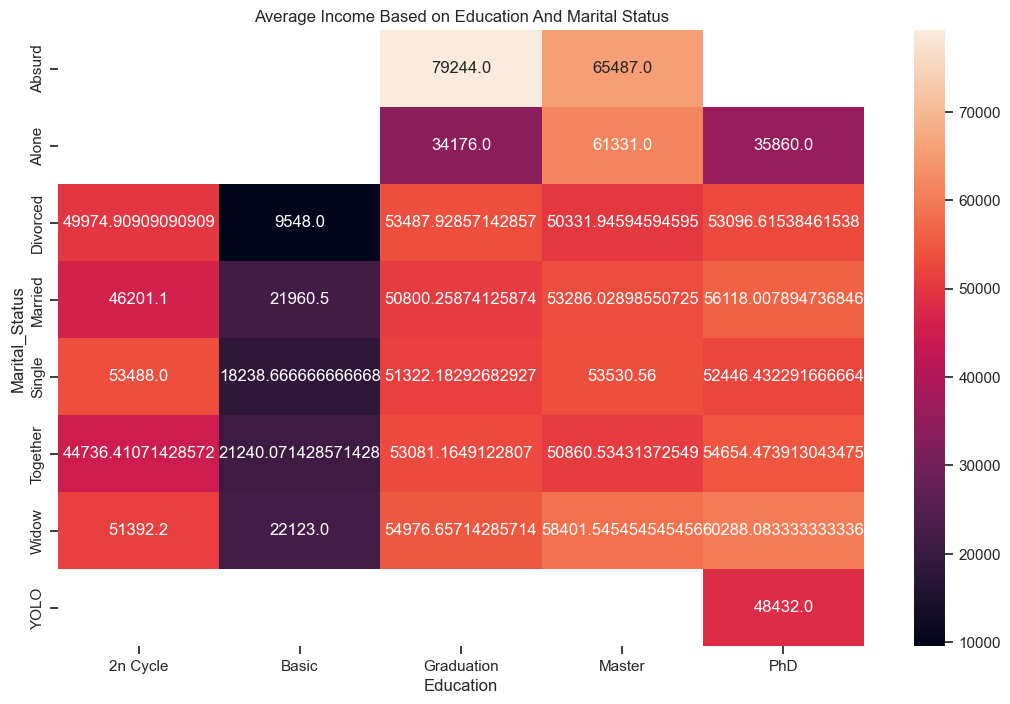

In [125]:
income=df.pivot_table(values='Income',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(13,8))
sns.heatmap(income, annot=True, fmt='')
plt.title("Average Income Based on Education And Marital Status")
plt.show()

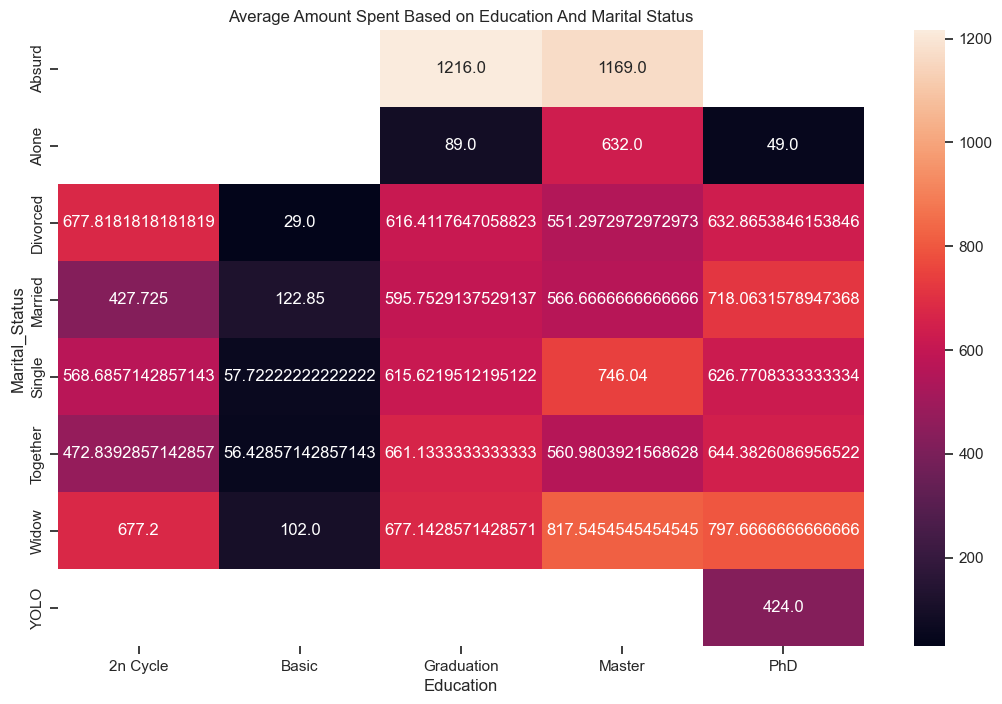

In [126]:
amount_spent=df.pivot_table(values='amount_spent',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(13,8))
sns.heatmap(amount_spent, annot=True, fmt='')
plt.title("Average Amount Spent Based on Education And Marital Status")
plt.show()

In [127]:
df.groupby('Education')[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases']].agg(['mean', 'count', 'sum'])

NumDealsPurchases             NumWebPurchases              \
                        mean count   sum            mean count   sum   
Education                                                              
2n Cycle            2.272727   198   450        3.787879   198   750   
Basic               1.796296    54    97        1.888889    54   102   
Graduation          2.311828  1116  2580        4.115591  1116  4593   
Master              2.424658   365   885        4.035616   365  1473   
PhD                 2.362500   480  1134        4.433333   480  2128   

           NumCatalogPurchases             NumStorePurchases              
                          mean count   sum              mean count   sum  
Education                                                                 
2n Cycle              2.373737   198   470          5.595960   198  1108  
Basic                 0.481481    54    26          2.851852    54   154  
Graduation            2.738351  1116  3056          5.841398  1116  6519  
Master                2.545205   365   929          5.887671   365  2149  
PhD                   2.981250   480  1431          6.077083   480  2917

In [128]:
df['purchases']= df.NumCatalogPurchases + df.NumDealsPurchases + df.NumStorePurchases + df.NumWebPurchases

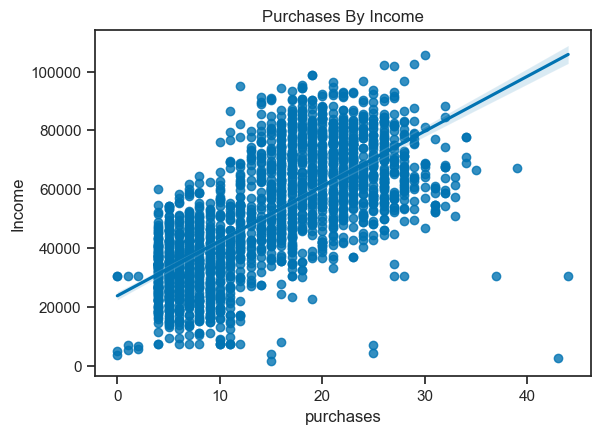

In [129]:
plt.figure(figsize=(6.4,4.5))

sns.regplot(data=df, x='purchases', y='Income')

plt.title('Purchases By Income')
plt.show()

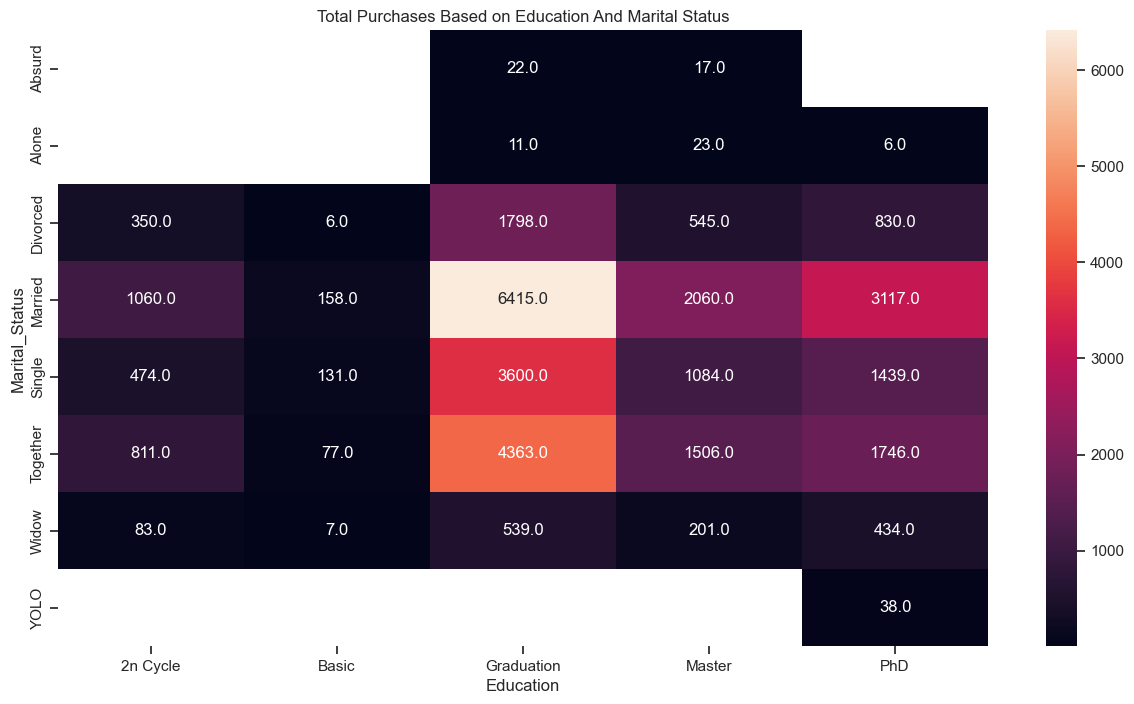

In [130]:
amount_spent=df.pivot_table(values='purchases',columns='Education',index='Marital_Status', aggfunc='sum')
plt.figure(figsize=(15,8))
sns.heatmap(amount_spent, annot=True, fmt='')
plt.title("Total Purchases Based on Education And Marital Status")
plt.show()

In [131]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'age', 'Children', 'amount_spent', 'campaign', 'purchases'],
      dtype='object')

In [132]:
df=df[['age','Education', 'Marital_Status', 'Income','amount_spent','purchases','NumWebVisitsMonth','campaign']]

In [133]:
df.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,Graduation,Single,58138.0,1617,25,7,0
1,72,Graduation,Single,46344.0,27,6,5,0
2,61,Graduation,Together,71613.0,776,21,4,0
3,42,Graduation,Together,26646.0,53,8,6,0
4,45,PhD,Married,58293.0,422,19,5,0


In [134]:
df.describe()

,age,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
count,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000
mean,57.082693,51507.673520,607.021690,14.889742,5.321735,0.298238
std,11.700216,20677.442707,602.488663,7.670341,2.425092,0.679446
min,30.000000,1730.000000,5.000000,0.000000,0.000000,0.000000
25%,49.000000,34935.000000,69.000000,8.000000,3.000000,0.000000
50%,56.000000,51141.000000,397.000000,15.000000,6.000000,0.000000
75%,67.000000,68142.000000,1048.000000,21.000000,7.000000,0.000000
max,86.000000,105471.000000,2525.000000,44.000000,20.000000,4.000000


In [135]:
corr= df.select_dtypes(include=np.number).corr()

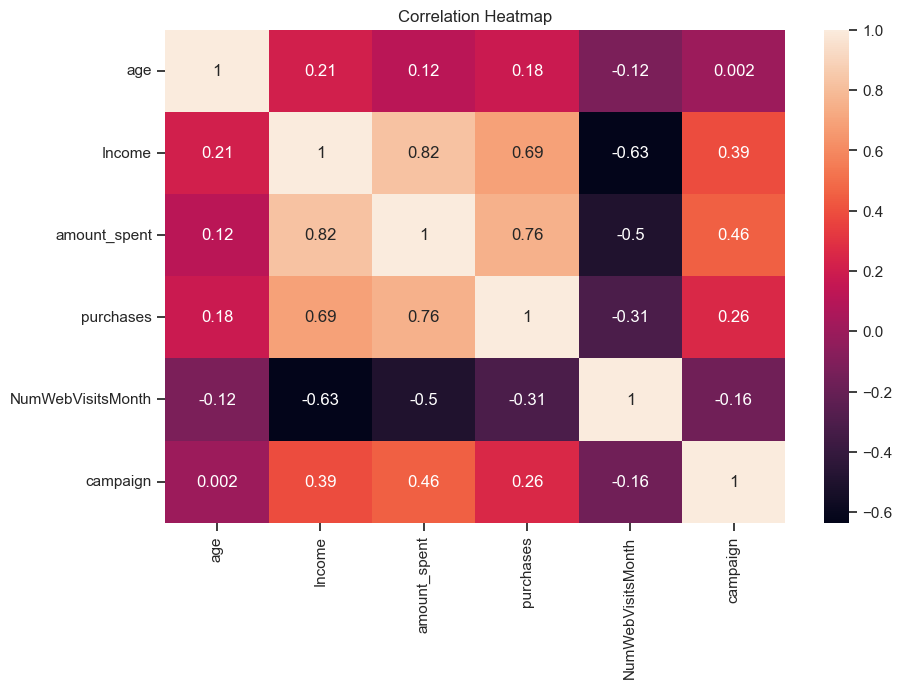

In [136]:
plt.figure(figsize=(10,6.4))


sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap')
plt.show()

# Preprocessing

In [137]:
df1= df.copy()
df1.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,Graduation,Single,58138.0,1617,25,7,0
1,72,Graduation,Single,46344.0,27,6,5,0
2,61,Graduation,Together,71613.0,776,21,4,0
3,42,Graduation,Together,26646.0,53,8,6,0
4,45,PhD,Married,58293.0,422,19,5,0


In [138]:
lb= LabelEncoder()
for col in df1.select_dtypes(include='object').columns:
  df1[col]= lb.fit_transform(df1[col])

In [139]:
df1.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,2,4,58138.0,1617,25,7,0
1,72,2,4,46344.0,27,6,5,0
2,61,2,5,71613.0,776,21,4,0
3,42,2,5,26646.0,53,8,6,0
4,45,4,3,58293.0,422,19,5,0


In [140]:
df1.isnull().sum()

age                  0
Education            0
Marital_Status       0
Income               0
amount_spent         0
purchases            0
NumWebVisitsMonth    0
campaign             0
dtype: int64

In [141]:
df1.dropna(inplace=True)

In [162]:
# Scaling

scale= StandardScaler()
x= scale.fit_transform(df1)

In [163]:
x

array([[ 1.01878463, -0.35245378,  0.25420246, ...,  1.31839545,
         0.69219825, -0.43904159],
       [ 1.2752481 , -0.35245378,  0.25420246, ..., -1.15923812,
        -0.13269929, -0.43904159],
       [ 0.33488204, -0.35245378,  1.18250285, ...,  0.79678838,
        -0.54514805, -0.43904159],
       ...,
       [-1.03292314, -0.35245378, -1.60239833, ...,  0.53598485,
         0.27974948,  1.03307817],
       [ 1.10427245,  0.53895218,  1.18250285, ...,  1.05759191,
        -0.95759682, -0.43904159],
       [ 1.2752481 ,  1.43035815, -0.67409794, ..., -0.50722928,
         0.69219825, -0.43904159]])

In [164]:
pca= PCA(n_components=2)
x_pca= pca.fit_transform(x)

In [165]:
scores= []
inertia= []

for i in range(2,11):
  model= KMeans(n_clusters=i, n_init=10, max_iter=300, init='k-means++', random_state= 42)
  labels = model.fit_predict(x)
  score=silhouette_score(x,labels)
  scores.append(score)
  inertia.append(model.inertia_)

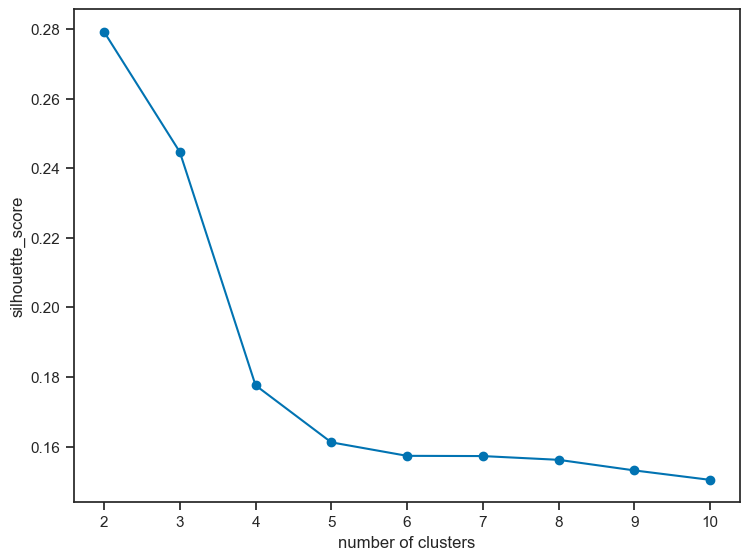

In [168]:
plt.figure(figsize=(8.6,6.4))
plt.plot(list(range(2,11)),scores, marker= 'o')

plt.xlabel('number of clusters')
plt.ylabel('silhouette_score')
plt.show()

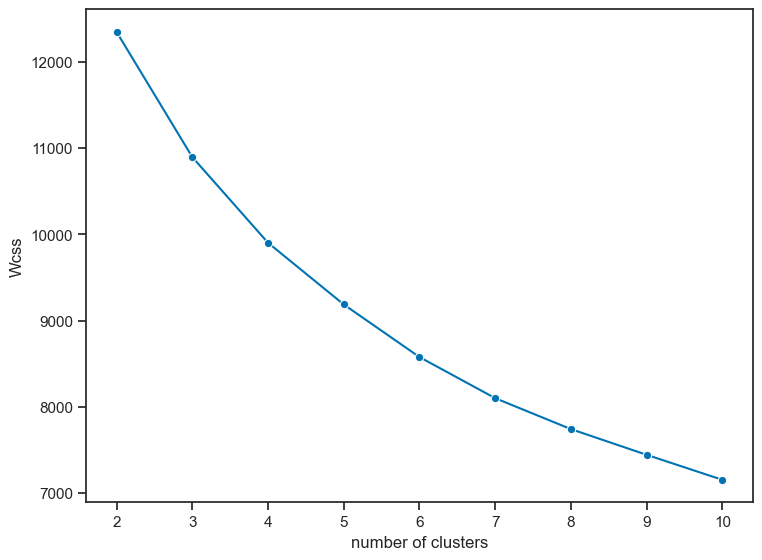

In [169]:
plt.figure(figsize=(8.6,6.4))
sns.lineplot(x=list(range(2,11)), y= inertia, marker='o')


plt.xlabel('number of clusters')
plt.ylabel('Wcss')
plt.show()
plt.show()

In [171]:
final_model= KMeans(n_clusters=5, max_iter=100, n_init=10, random_state=42, init='k-means++').fit(x)

In [172]:
df['Cluster']= final_model.predict(x)

In [173]:
df['Cluster'].value_counts()

Cluster
4    607
1    505
0    490
3    482
2    129
Name: count, dtype: int64

In [174]:
df['x'], df['y']= x_pca[:,0],x_pca[:,1]

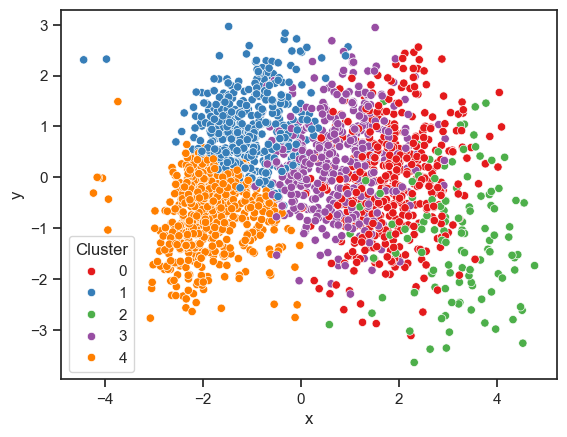

In [176]:
plt.Figure(figsize=(6.4,4.6))

sns.scatterplot(x='x', y='y', data=df, hue='Cluster', palette='Set1')

plt.show()

In [180]:
features= df.drop(columns=['Cluster', 'Education', 'Marital_Status']).columns
cluster_features= df.groupby('Cluster')[features].mean()

In [181]:
round(cluster_features, 2)

,age,Income,amount_spent,purchases,NumWebVisitsMonth,campaign,x,y
Cluster,,,,,,,,
0,57.99,73902.55,1244.39,20.51,2.49,0.25,1.87,-0.07
1,62.33,40384.01,143.33,9.22,5.94,0.09,-1.08,0.95
2,55.81,80472.40,1577.12,21.13,3.58,2.51,3.14,-1.15
3,61.71,58898.49,815.65,22.00,6.02,0.24,0.73,0.29
4,48.58,30659.46,106.45,8.10,6.91,0.09,-1.86,-0.72


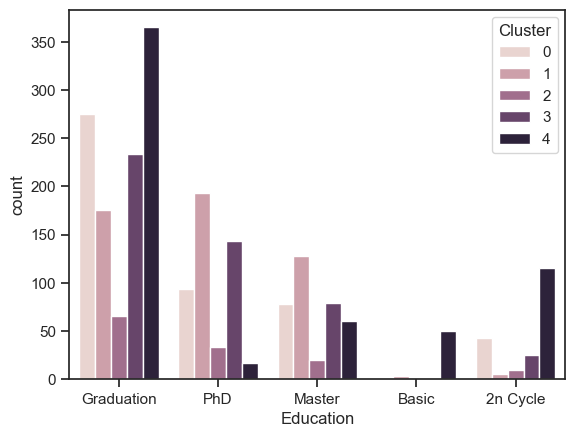

In [186]:
sns.countplot(data=df, x='Education', hue='Cluster')

plt.show()

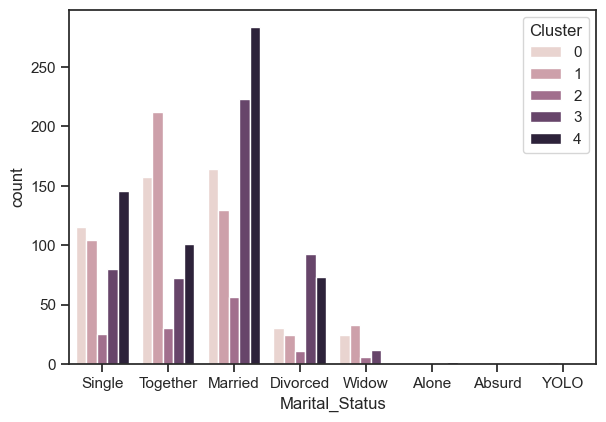

In [185]:
plt.figure(figsize=(6.8,4.6))
sns.countplot(data=df, x='Marital_Status', hue='Cluster')

plt.show()

In [184]:
df[['Cluster','Marital_Status','Education']].value_counts().unstack(-1)

Education               2n Cycle  Basic  Graduation  Master   PhD
Cluster Marital_Status                                           
0       Divorced             1.0    NaN        18.0     5.0   6.0
        Married             18.0    NaN        89.0    24.0  33.0
        Single               9.0    NaN        65.0    24.0  17.0
        Together            13.0    NaN        90.0    23.0  31.0
        Widow                2.0    NaN        13.0     2.0   7.0
1       Divorced             NaN    NaN         5.0     5.0  14.0
        Married              NaN    NaN        30.0    34.0  66.0
        Single               1.0    NaN        30.0    29.0  44.0
        Together             2.0    2.0        96.0    54.0  58.0
        Widow                2.0    1.0        15.0     6.0   9.0
        YOLO                 NaN    NaN         NaN     NaN   2.0
2       Absurd               NaN    NaN         1.0     NaN   NaN
        Divorced             2.0    NaN         7.0     1.0   1.0
        Married              4.0    NaN        26.0     8.0  18.0
        Single               3.0    NaN        12.0     4.0   6.0
        Together             1.0    NaN        18.0     5.0   6.0
        Widow                NaN    NaN         2.0     2.0   2.0
3       Absurd               NaN    NaN         NaN     1.0   NaN
        Alone                NaN    NaN         NaN     1.0   NaN
        Divorced             9.0    NaN        43.0    14.0  27.0
        Married              7.0    1.0       111.0    41.0  63.0
        Single               1.0    NaN        45.0     7.0  27.0
        Together             8.0    NaN        30.0    14.0  20.0
        Widow                NaN    NaN         5.0     1.0   6.0
4       Alone                NaN    NaN         1.0     NaN   1.0
        Divorced            10.0    1.0        46.0    12.0   4.0
        Married             51.0   19.0       173.0    31.0  10.0
        Single              21.0   18.0        94.0    11.0   2.0
        Together            32.0   12.0        51.0     6.0   NaN
        Widow                1.0    NaN         NaN     NaN   NaN

> INSIGHT

* Cluster 4  they have highest number of web visits, the youngest in age and earns the lowest, with the highest number of graduation, basic and 2n cycle holders and are mostly married
* Clusrer 1  they rank oldest with the second least income, amount spent and number of purchases, also the highest number of Phd and masters holders
* Cluster 3 highest number of purchases and  second hisgest number of web visits
* Cluster 2 are the highest earners, campaings accepted and spenders,they also rank second in number of purchases
* Cluster 0 are the second highest earners and spenders,they also rank third in number of purchases

In [187]:
joblib.dump(final_model,r"C:\Users\MINE\Desktop\Customer Segmentation\model.pkl")

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\model.pkl']

In [188]:
joblib.dump(scale,r"C:\Users\MINE\Desktop\Customer Segmentation\scale.pkl")

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\scale.pkl']

In [189]:
joblib.dump(lb,r"C:\Users\MINE\Desktop\Customer Segmentation\encoder.pkl")

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\encoder.pkl']

In [190]:
df.to_csv(r"C:\Users\MINE\Desktop\Customer Segmentation\clustered.csv")